# Bab 8 — Learning signal and ignoring noise: introduction to regularization and batching

**Mahasiswa:** Tarannia Raisha Putri · 101032300231 · TK4702 · Deep Learning

**Referensi utama:** Andrew W. Trask, *Grokking Deep Learning*, Manning (2019), Bab 8, halaman cetak 145–160 (PDF 166–181, indeks PDF mulai 1). Subbab spesifik dicantumkan pada setiap tahap.

**Tujuan pembelajaran:** Membandingkan training dan evaluasi, menurunkan dropout, serta membedakan update per-contoh dan per-batch.

## Ringkasan

Training error yang kecil tidak menjamin jaringan memahami pola yang bertahan pada data baru. Buku memperkenalkan overfitting, early stopping, dropout, dan mini-batch pada MNIST. Kita mempertahankan model NumPy tanpa TensorFlow untuk melatihnya.

## Konsep, intuisi, dan notasi

Untuk $B$ gambar: $X\in\mathbb R^{B\times784}$, $W_0\in\mathbb R^{784\times H}$, $W_1\in\mathbb R^{H\times10}$. Target one-hot $Y\in\mathbb R^{B\times10}$. Buku memakai output linear dan squared error, jadi argmax menentukan kelas tanpa menganggap output probabilitas.

Inverted dropout: $M_{ij}\sim\mathrm{Bernoulli}(q)$, $\tilde H=H\odot M/q$. Dengan $q=0.5$, faktor pengali 2 menjaga ekspektasi aktivasi. Saat evaluasi, gunakan seluruh H tanpa masker. Turunan yang konsisten adalah $D_H=(D_2W_1^T)\odot M/q\odot\operatorname{ReLU}'(Z)$.

Untuk loss rata-rata $\frac1{2B}\sum\|\hat y-y\|^2$, output delta dibagi B **sekali**. Update batch memakai matriks seluruh contoh; loop penghitung akurasi tidak boleh menyebabkan update berulang. Overfitting terlihat melalui gap/generalization curve, bukan sekadar jumlah parameter yang besar.

## Persiapan dan cara membaca

Jalankan **Restart Kernel → Run All**. Semua penjelasan merupakan parafrasa orisinal; angka hasil berada pada output sel yang benar-benar dijalankan. Label **reproduksi** berarti algoritme/contoh buku ditulis ulang; **koreksi/penyesuaian** menunjukkan perubahan; **tambahan** menunjukkan eksperimen atau interpretasi praktikum. `GDL_MODE=quick` mengurangi latihan berat; `full` memilih anggaran buku, dengan perubahan yang tetap dicatat. Keberhasilan eksekusi tidak membuktikan kesamaan akurasi dengan buku.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Jalankan dari root repository atau notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
MODE = os.environ.get('GDL_MODE', 'quick')
assert MODE in {'quick', 'full'}
FULL = MODE == 'full'
np.random.seed(1)
np.set_printoptions(precision=6, suppress=True)
METRICS = {}
def record(**values):
    METRICS.update(values)
def finite(*arrays):
    assert all(np.isfinite(np.asarray(a)).all() for a in arrays), 'NaN/inf terdeteksi'
def softmax(z):
    z = np.asarray(z)
    e = np.exp(z - np.max(z, axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)
def sigmoid(z):
    return np.exp(-np.logaddexp(0, -np.asarray(z)))
print('Mode:', MODE, '| NumPy:', np.__version__)

Mode: quick | NumPy: 2.5.4


<a id="b08-data"></a>

## Reproduksi: three-layer network on MNIST

**Sumber:** cetak 146–148; PDF 167–169.

Loader mengambil berkas `mnist.npz` yang dipakai distribusi Keras langsung dan memeriksa checksum; ini penggantian API pemuatan, bukan penggantian dataset. Buku menggunakan 1.000 contoh training awal. Mode ringan tetap memakai 1.000 contoh itu tetapi hanya 500 contoh test; mode penuh memakai 10.000 test. Validation tambahan tidak termasuk keduanya.

MNIST asli: train (1000, 784) validation (200, 784) test (500, 784)
10 label awal: [5 0 4 1 9 2 1 3 1 4]


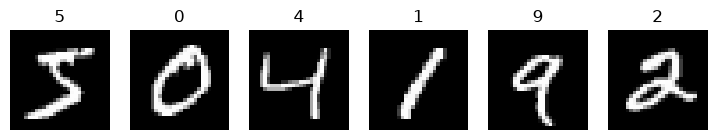

In [2]:
from src.datasets import mnist
x_train,y_train,x_test,y_test=mnist()
N=1000
images=x_train[:N].reshape(N,-1).astype(float)/255
labels=np.eye(10)[y_train[:N]]
# Validation tambahan berasal dari bagian training resmi di luar 1.000 contoh latihan.
validation=x_train[1000:1200].reshape(200,-1).astype(float)/255
validation_labels=np.eye(10)[y_train[1000:1200]]
T=10000 if FULL else 500
test_images=x_test[:T].reshape(T,-1).astype(float)/255
test_labels=np.eye(10)[y_test[:T]]
assert images.shape==(1000,784) and labels.shape==(1000,10)
finite(images,labels,test_images)
print('MNIST asli: train',images.shape,'validation',validation.shape,'test',test_images.shape)
print('10 label awal:',y_train[:10])
fig,axes=plt.subplots(1,6,figsize=(9,2))
for i,ax in enumerate(axes): ax.imshow(x_train[i],cmap='gray'); ax.set_title(str(y_train[i])); ax.axis('off')
plt.show()

<a id="b08-baseline"></a>

## Reproduksi: baseline, memorization, dan generalization

**Sumber:** cetak 147–152; PDF 168–173.

Fungsi berikut memperlihatkan forward, delta, dan update. Penghitungan metrik dilakukan setelah satu epoch dengan bobot tetap, berbeda dari running training accuracy listing. `book_dropout=True` mempertahankan faktor gradien masker listing; versi koreksi memakai M/q. Baseline: hidden 40, alpha 0,005, 350 epoch penuh atau 30 ringan.

In [3]:
def scores(X,Y,W0,W1):
    p=np.maximum(0,X@W0)@W1
    return float(np.mean(np.sum((p-Y)**2,axis=1))),float(np.mean(p.argmax(1)==Y.argmax(1)))
def train_mlp(epochs,hidden=40,batch=1,alpha=.005,dropout=False,book_dropout=False):
    rng=np.random.RandomState(1)
    W0=.2*rng.rand(784,hidden)-.1; W1=.2*rng.rand(hidden,10)-.1
    log=[]; best=(float('inf'),None,None,0)
    for epoch in range(epochs):
        for start in range(0,len(images),batch):
            X=images[start:start+batch]; Y=labels[start:start+batch]
            pre=X@W0; H=np.maximum(0,pre)
            mask=rng.randint(2,size=H.shape) if dropout else np.ones_like(H)
            scale=mask*2 if dropout else mask
            Hd=H*scale; pred=Hd@W1
            d2=(pred-Y)/len(X)
            backward_mask=mask if book_dropout else scale
            d1=(d2@W1.T)*(pre>0)*backward_mask
            G0=X.T@d1; G1=Hd.T@d2
            W0-=alpha*G0; W1-=alpha*G1
        train_loss,train_acc=scores(images,labels,W0,W1)
        val_loss,val_acc=scores(validation,validation_labels,W0,W1)
        log.append([train_loss,train_acc,val_loss,val_acc])
        if val_loss<best[0]: best=(val_loss,W0.copy(),W1.copy(),epoch+1)
    finite(W0,W1,log)
    return W0,W1,np.array(log),best
base=train_mlp(350 if FULL else 30)
print('Baseline akhir [train SSE,acc,val SSE,acc]:',base[2][-1])
print('Test baseline:',scores(test_images,test_labels,*base[:2]))

Baseline akhir [train SSE,acc,val SSE,acc]: [0.090788 0.992    0.358222 0.825   ]
Test baseline: (0.3055590179640119, 0.842)


<a id="b08-dropout"></a>

## Reproduksi: ensembling, masker dropout, evaluasi

**Sumber:** cetak 153–157; PDF 174–178.

Dropout melatih subnet acak yang berbagi bobot; analogi ensemble menjelaskan pengurangan ketergantungan pada satu neuron, tetapi bukan rata-rata eksplisit semua model independen. Listing cetak memakai `mask` pada backward walau forward dikali `2*mask`. Di sini kedua versi dijalankan dan diberi label. Seed dan urutan input sama; jangan menyimpulkan dropout unggul dari satu run pendek.

In [4]:
activation=np.array([[1.,2.,3.,4.]])
mask=np.array([[1.,0.,1.,0.]])
print('Masker contoh tambahan:',activation*mask*2)
rng=np.random.RandomState(1)
mean_masked=(activation*rng.randint(2,size=(10000,4))*2).mean(0)
print('Ekspektasi empiris tambahan:',mean_masked)
drop_book=train_mlp(300 if FULL else 20,hidden=100,dropout=True,book_dropout=True)
drop_fixed=train_mlp(300 if FULL else 20,hidden=100,dropout=True)
for name,result in [('listing_dropout',drop_book),('koreksi_dropout',drop_fixed)]:
    print(name,'akhir:',result[2][-1], 'test:',scores(test_images,test_labels,*result[:2]))

Masker contoh tambahan: [[2. 0. 6. 0.]]
Ekspektasi empiris tambahan: [1.0068 2.03   2.9898 3.9616]


listing_dropout akhir: [0.190658 0.96     0.3616   0.81    ] test: (0.3505281170774013, 0.846)
koreksi_dropout akhir: [0.153895 0.971    0.350487 0.83    ] test: (0.32063710633095355, 0.854)


<a id="b08-batch"></a>

## Reproduksi: mini-batch; tambahan early stopping

**Sumber:** cetak 158–160; PDF 179–181.

Listing PDF menempatkan update setelah loop akurasi; notebook upstream mengindentasinya ke dalam loop. Implementasi ini mengikuti PDF: satu update per batch. Versi buku memakai alpha=0,001 dan backward masker tanpa faktor 2. Eksperimen koreksi memakai alpha=0,1, sebab merata-ratakan gradien sekaligus mengurangi jumlah update dapat membuat langkah terlalu kecil.

Early stopping dibahas secara konseptual pada halaman 152. **Tambahan implementasi:** pilih snapshot dengan validation SSE minimum, lalu evaluasi test sekali pada snapshot terpilih. Kurva validation boleh berfluktuasi; minimum bukan bukti bahwa nilai yang sama akan bertahan pada test.

batch_listing test: (0.9472832340548412, 0.232)
batch_koreksi test: (0.3708790521961305, 0.828)
Early stopping tambahan: epoch 20 validation SSE 0.3535064086007622 test (0.30662506156623465, 0.858)


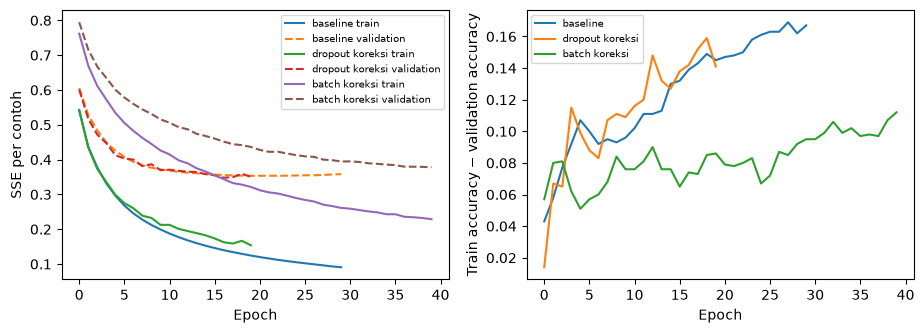

Analisis aktual: gap baseline = 0.16700000000000004 ; titik validation minimum epoch 20
Kurva pendek belum cukup untuk menjamin terlihatnya overfitting yang kuat.


In [5]:
batch_book=train_mlp(300 if FULL else 40,hidden=100,batch=100,alpha=.001,dropout=True,book_dropout=True)
batch_fixed=train_mlp(300 if FULL else 40,hidden=100,batch=100,alpha=.1,dropout=True)
for name,result in [('batch_listing',batch_book),('batch_koreksi',batch_fixed)]:
    print(name,'test:',scores(test_images,test_labels,*result[:2]))
best=base[3]
best_test=scores(test_images,test_labels,best[1],best[2])
print('Early stopping tambahan: epoch',best[3],'validation SSE',best[0],'test',best_test)
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
for name,result in [('baseline',base),('dropout koreksi',drop_fixed),('batch koreksi',batch_fixed)]:
    axes[0].plot(result[2][:,0],label=name+' train')
    axes[0].plot(result[2][:,2],ls='--',label=name+' validation')
    axes[1].plot(result[2][:,1]-result[2][:,3],label=name)
axes[0].set(xlabel='Epoch',ylabel='SSE per contoh'); axes[1].set(xlabel='Epoch',ylabel='Train accuracy − validation accuracy')
for ax in axes: ax.legend(fontsize=7)
plt.show()
gap=float(base[2][-1,1]-base[2][-1,3])
print('Analisis aktual: gap baseline =',gap,'; titik validation minimum epoch',best[3])
print('Kurva pendek belum cukup untuk menjamin terlihatnya overfitting yang kuat.')
record(train_count=N,test_count=T,baseline_epochs=len(base[2]),baseline_test_accuracy=scores(test_images,test_labels,*base[:2])[1],dropout_test_accuracy=scores(test_images,test_labels,*drop_fixed[:2])[1],batch_test_accuracy=scores(test_images,test_labels,*batch_fixed[:2])[1],early_stopping_epoch=best[3],baseline_gap=gap)

## Analisis output aktual — run tersimpan

Mode **quick**, eksekusi 2026-10-16T01:50:20.543019+07:00. Ringkasan ini dibuat dari output validator, bukan angka contoh dalam buku.

Pada 500 gambar test, baseline 84.2%, dropout koreksi 85.4%, dan mini-batch koreksi 82.8%. Gap train-validation baseline 16.7%; validation memilih epoch 20 dari 30. Perbandingan ini juga melibatkan hidden size/alpha/jumlah update berbeda, sehingga bukan ablation dropout yang terkontrol.

## Kesimpulan dan pembahasan pertanyaan

Notebook menjalankan seluruh jenis latihan inti Bab 8. Plot memakai output lokal, bukan angka buku. Mode ringan menguji mekanisme dan kurva awal; klaim reproduksi hasil 300–350 epoch memerlukan mode penuh.

**Mengapa dropout dimatikan saat test?** Inverted scaling sudah menjaga ekspektasi saat training; evaluasi memakai jaringan utuh.

**Mengapa test tidak dipakai memilih epoch?** Itu memasukkan informasi evaluasi ke pemilihan model dan membuat estimasi generalisasi optimistis.

**Apakah satu epoch batch sama dengan satu epoch SGD?** Tidak; jumlah dan urutan update berbeda walau semua contoh dikunjungi.

In [6]:
finite(*[v for v in METRICS.values() if isinstance(v, (int, float))])
print('VALIDATION_METRICS=' + json.dumps(METRICS, sort_keys=True))

VALIDATION_METRICS={"baseline_epochs": 30, "baseline_gap": 0.16700000000000004, "baseline_test_accuracy": 0.842, "batch_test_accuracy": 0.828, "dropout_test_accuracy": 0.854, "early_stopping_epoch": 20, "test_count": 500, "train_count": 1000}
